# 01 Exploratory Analysis

Hourly traffic for three zones (Duomo, San Siro, Bocconi), Milan, 1 Nov 2013 – 1 Jan 2014. This notebook characterises seasonality, the holiday regime and stationarity, and motivates the lags and calendar features used in 03.

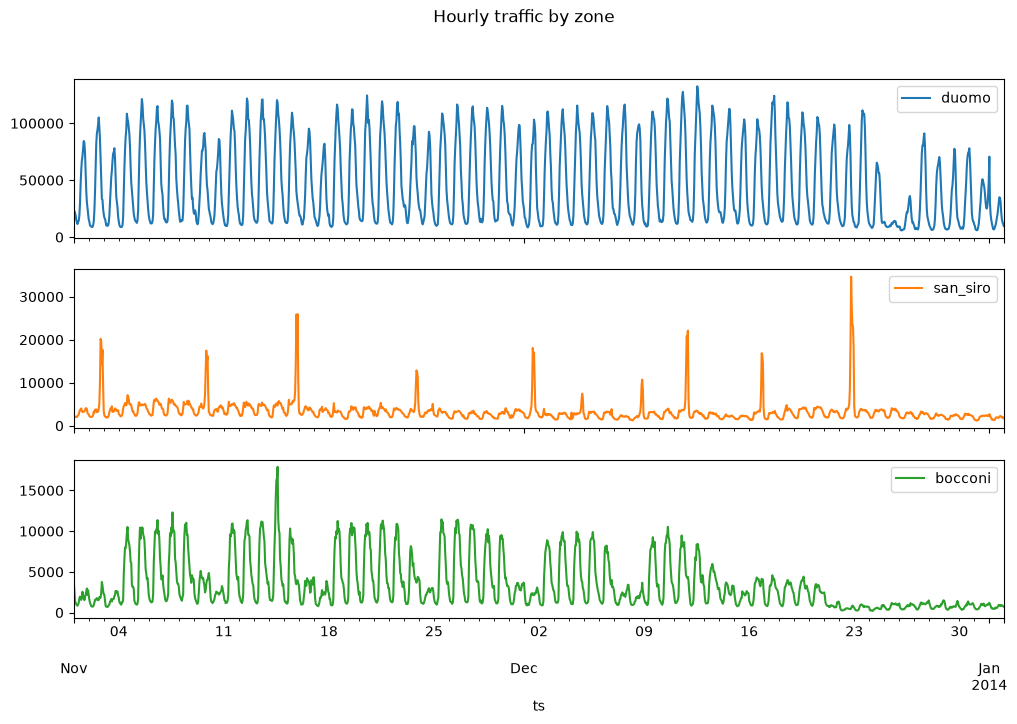

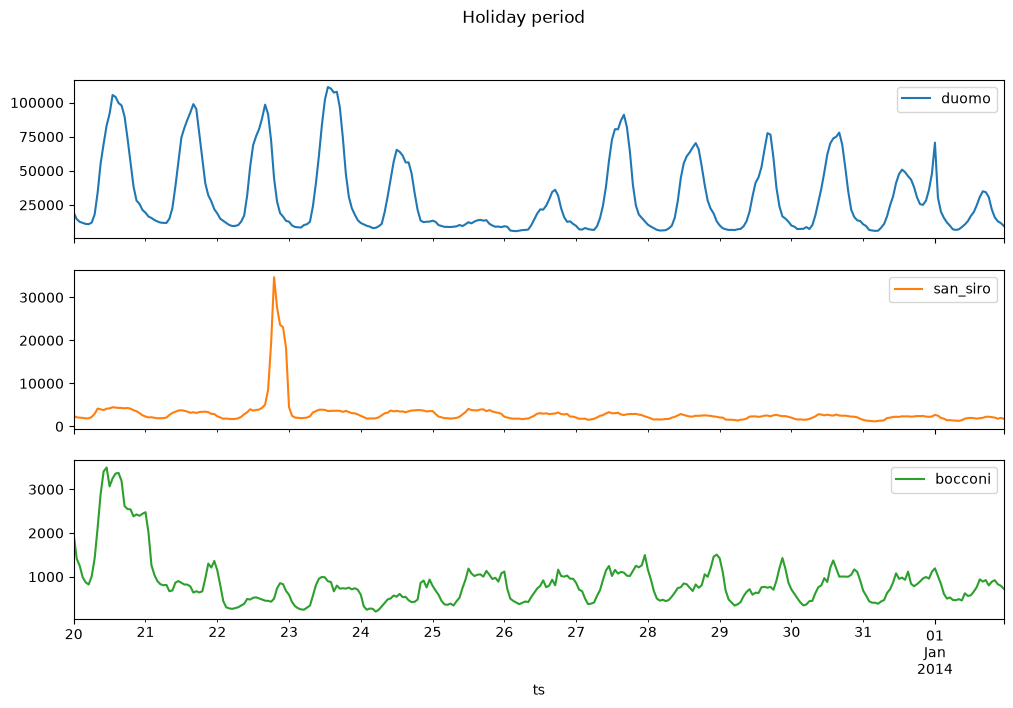

In [1]:
import warnings
import matplotlib.pyplot as plt
import pandas as pd
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tools.sm_exceptions import InterpolationWarning
from statsmodels.tsa.seasonal import MSTL, STL
from statsmodels.tsa.stattools import adfuller, kpss

zones = pd.read_csv("../data/processed/milan_zones_hourly.csv", index_col="ts", parse_dates=True)
duomo, san = zones["duomo"], zones["san_siro"]

zones.plot(subplots=True, figsize=(12, 7), sharex=True, title="Hourly traffic by zone")
plt.show()

zones.loc["2013-12-20":"2014-01-01"].plot(subplots=True, figsize=(12, 7), sharex=True, title="Holiday period")
plt.show()

## Zone Overwiev
Duomo shows a regular daily cycle (peaks around 100k) that shrinks sharply after about 20 Dec; 25 Dec is close to zero. 
San Siro is flat apart from isolated match-night spikes. Bocconi drops to a lower level from about 21 Dec

## San Siro match-night spikes
Days whose peak exceeds 3× the median traffic are all match days (9 of the 10 matches). The threshold misses Inter–Trapani on 4 Dec, a low-profile match, which is why detection is evaluated with windows in notebook 04.

ts
2013-12-22 19:00:00    34664.929822
2013-12-22 20:00:00    27640.765834
2013-12-22 21:00:00    23607.820715
2013-12-22 22:00:00    23056.520655
2013-12-22 18:00:00    19226.199452
Name: san_siro, dtype: float64


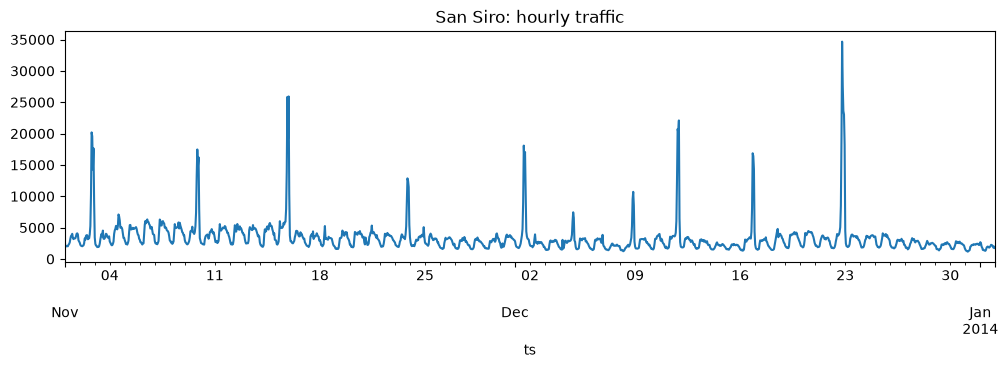

In [2]:
print(san.loc["2013-12-22"].nlargest(5))
san.plot(figsize=(12, 3), title="San Siro: hourly traffic")
plt.show()

In [3]:
daily_max = san.resample("D").max()
spikes = daily_max[daily_max > 3 * san.median()]
print(spikes.round(0).to_frame("peak").assign(weekday=spikes.index.day_name()))

               peak    weekday
ts                            
2013-11-02  20189.0   Saturday
2013-11-09  17467.0   Saturday
2013-11-15  25924.0     Friday
2013-11-23  12854.0   Saturday
2013-12-01  18081.0     Sunday
2013-12-08  10706.0     Sunday
2013-12-11  22096.0  Wednesday
2013-12-16  16858.0     Monday
2013-12-22  34665.0     Sunday


### Is the surge local? 
On 11 Dec (Milan–Ajax, 20:45 kick-off) San Siro’s top hours are 20:00–22:00, while Duomo and Bocconi peak around midday. The surge is local, not city-wide.

In [4]:
day = zones.loc["2013-12-11"]
print(day.idxmax()) # peak hour per zone
print(san.loc["2013-12-11"].nlargest(5))

duomo      2013-12-11 14:00:00
san_siro   2013-12-11 22:00:00
bocconi    2013-12-11 12:00:00
dtype: datetime64[us]
ts
2013-12-11 22:00:00    22095.938384
2013-12-11 20:00:00    20720.747272
2013-12-11 21:00:00    20166.627339
2013-12-11 19:00:00    12680.354220
2013-12-11 23:00:00     6429.934670
Name: san_siro, dtype: float64


## Seasonal decomposition (Duomo)
MSTL with daily (24 h) and weekly (168 h) periods. The trend bends down after about 18 Dec because of the holiday regime, not a long-run trend; residuals widen around 22–25 Dec.

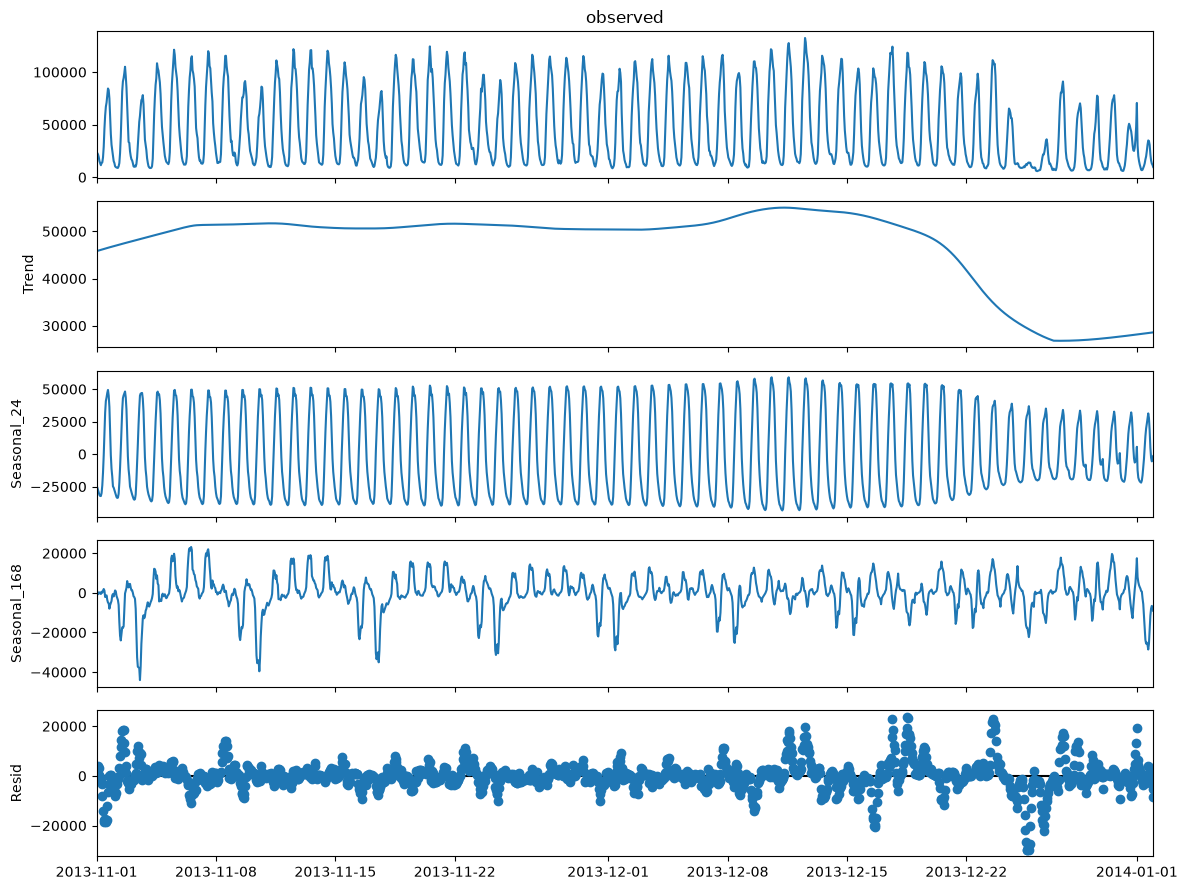

In [5]:
duomo = zones["duomo"]
res = MSTL(duomo, periods=(24, 168)).fit()
fig = res.plot()
fig.set_size_inches(12, 9)
fig.tight_layout()

## Stationarity 
ADF and KPSS agree that the pre-holiday series is stationary (ADF p = 0.0007, KPSS p ≥ 0.10, bounded) and differencing does not change this. Including the holiday weeks weakens the ADF evidence (p = 0.035). A persistent seasonal pattern is not a unit root, so seasonality is handled with lags and calendar features instead of differencing.

In [6]:
def stationarity(s, name):
    s = s.dropna()
    adf_p = adfuller(s, result_object=True).pvalue
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", InterpolationWarning)
        kpss_p = kpss(s, regression="c", nlags="auto", result_object=True).pvalue
    print(f"{name:28s} ADF p={adf_p:.4f} | KPSS p={kpss_p:.4f} (bounded)")

normal = duomo.loc[:"2013-12-19"]  # pre-holiday regime
stationarity(normal, "raw (to 19 Dec)")
stationarity(normal.diff(24), "diff(24)")
stationarity(normal.diff(24).diff(168), "diff(24) + diff(168)")
stationarity(duomo, "full series incl. holidays")

raw (to 19 Dec)              ADF p=0.0007 | KPSS p=0.1000 (bounded)
diff(24)                     ADF p=0.0000 | KPSS p=0.1000 (bounded)
diff(24) + diff(168)         ADF p=0.0000 | KPSS p=0.1000 (bounded)
full series incl. holidays   ADF p=0.0347 | KPSS p=0.0100 (bounded)


## ACF / PACF 
ACF oscillates with a 24 h period and barely decays up to 192 lags; the weekly peak (168 h) is slightly higher. PACF is dominated by lags 1–2, with a significant dip at 24–25. Lags 24, 48 and 168 are used as features. Lags 1–2 are excluded because the forecast horizon is 24 h.

## STL: Duomo vs San Siro

Robust STL with a 24 h period, applied to both zones to compare their residual structure.

- San Siro: the residual is flat apart from isolated positive spikes on match nights, up to about 30k on 22 Dec against a baseline of roughly 2–5k. The daily seasonal component captures the routine cycle, and its amplitude shrinks slowly over the period.
- Duomo: a 24 h seasonal component alone leaves a clear weekend signal in the residual because the weekly cycle is not modelled. Up to 19 Dec the mean residual is about −5.8k on Saturdays and −11.2k on Sundays, against −0.9k to +1.0k on other days. The largest positive residuals fall around 22–23 Dec and on New Year's Eve; 25–26 Dec appears as a deep dip.

### Consequence 
a residual-based detector works on San Siro's flat baseline, but on Duomo it would flag weekends unless the weekly component is modelled (see the MSTL decomposition above).

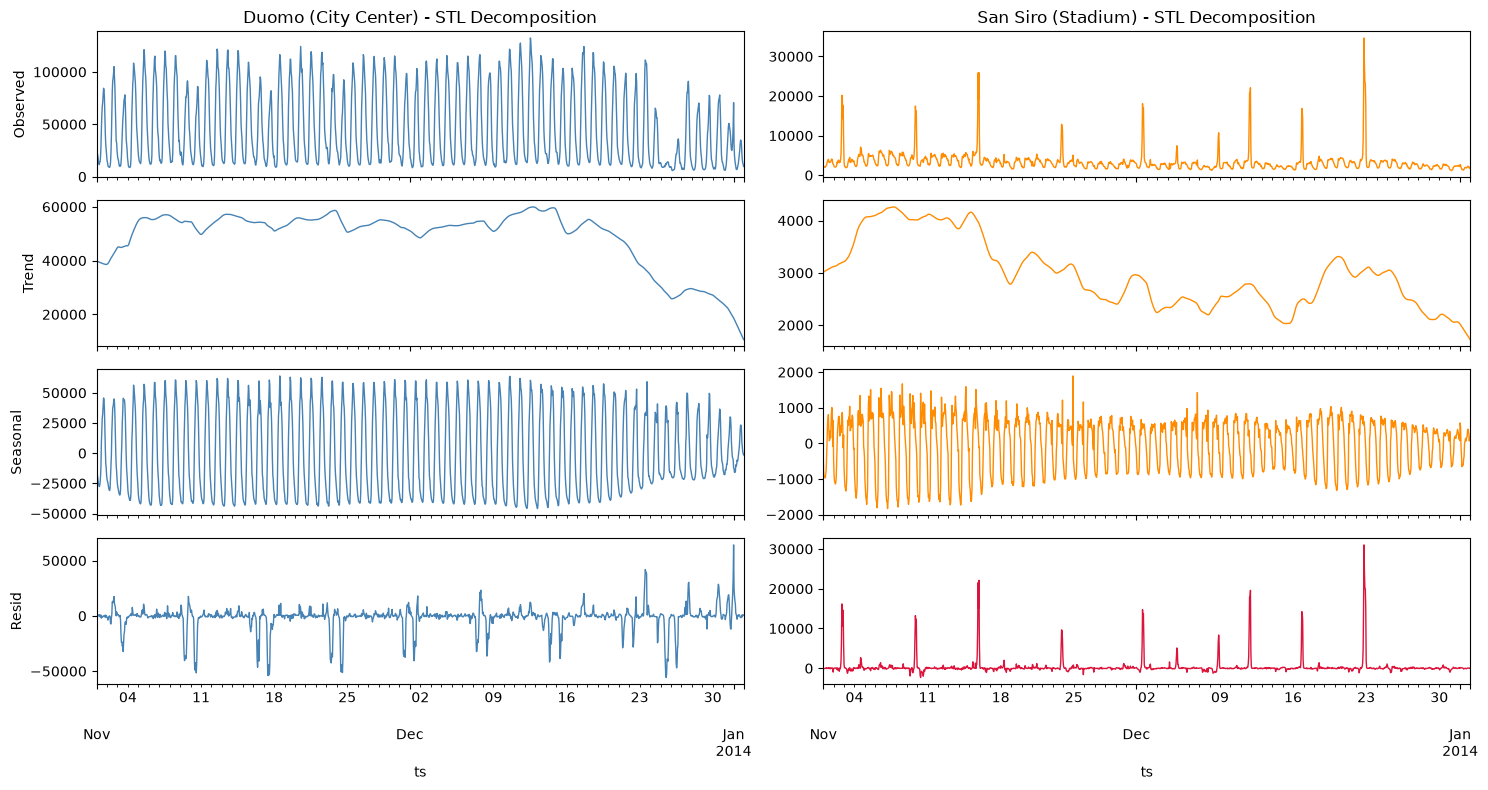

In [7]:
# Daily cycle (period=24) with robust fitting to isolate extreme spikes in residuals
stl_duomo = STL(duomo.dropna(), period=24, robust=True).fit()
stl_sansiro = STL(san.dropna(), period=24, robust=True).fit()

fig, axes = plt.subplots(4, 2, figsize=(15, 8), sharex=True)
components = ["observed", "trend", "seasonal", "resid"]

for i, comp in enumerate(components):
    getattr(stl_duomo, comp).plot(ax=axes[i, 0], color="steelblue", lw=1)
    axes[i, 0].set_ylabel(comp.capitalize())

    color = "crimson" if comp == "resid" else "darkorange"
    getattr(stl_sansiro, comp).plot(ax=axes[i, 1], color=color, lw=1)

axes[0, 0].set_title("Duomo (City Center) - STL Decomposition")
axes[0, 1].set_title("San Siro (Stadium) - STL Decomposition")
plt.tight_layout()
plt.show()

In [8]:
r = stl_duomo.resid.loc[:"2013-12-19"]
weekday = r.groupby(r.index.day_of_week).mean().round(0)
weekday.index = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
weekday

Mon      213.0
Tue     1000.0
Wed      719.0
Thu      764.0
Fri     -896.0
Sat    -5807.0
Sun   -11245.0
Name: resid, dtype: float64

## Takeaways
- Daily and weekly seasonality → lag_24/48/168 and calendar features. Holiday weeks form a different regime → evaluated separately. San Siro’s flat baseline and match-night spikes → anomaly detection in 04.
- Residual-based detection depends on modelling the weekly cycle where it is strong (Duomo) but not where the baseline is flat (San Siro).